

#### Tasks:


The [CIFAR-10 dataset](https://www.cs.toronto.edu/~kriz/cifar.html) consists of 60000 $32 \times 32$ colour images in 10 classes, with 6000 images per class. There are 50000 training images and 10000 test images.

Following lab examples, build a deep neural network model to predict image class.




## Step 0: Set up the programming environment

In [3]:
# import data munging libraries

import pandas as pd
import numpy as np

# import drawing libraries and configure drawing settings

import matplotlib.pyplot as plt
plt.style.use('seaborn-white')
%config InlineBackend.figure_format = "retina"


# import tensorflow and keras API

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, losses, optimizers, callbacks, regularizers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Flatten, BatchNormalization


<ipython-input-3-7f5a859cffc6>:9: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.style.use('seaborn-white')


---

## Step 1: Import and Explore Data

In [4]:
(X_train, y_train), (X_valid, y_valid) = keras.datasets.cifar10.load_data()

print (f"Each image is of size: {X_train.shape[1:]}")
print (f"X_train's shape: {X_train.shape}"  )
print (f"X_valid's shape: {X_valid.shape}" + str())
print (f"y_train's shape: {y_train.shape}")
print (f"y_valid's shape: {y_valid.shape}" )

170498071/170498071 [==============================] - 4s 0us/step
Each image is of size: (32, 32, 3)
X_train's shape: (50000, 32, 32, 3)
X_valid's shape: (10000, 32, 32, 3)
y_train's shape: (50000, 1)
y_valid's shape: (10000, 1)


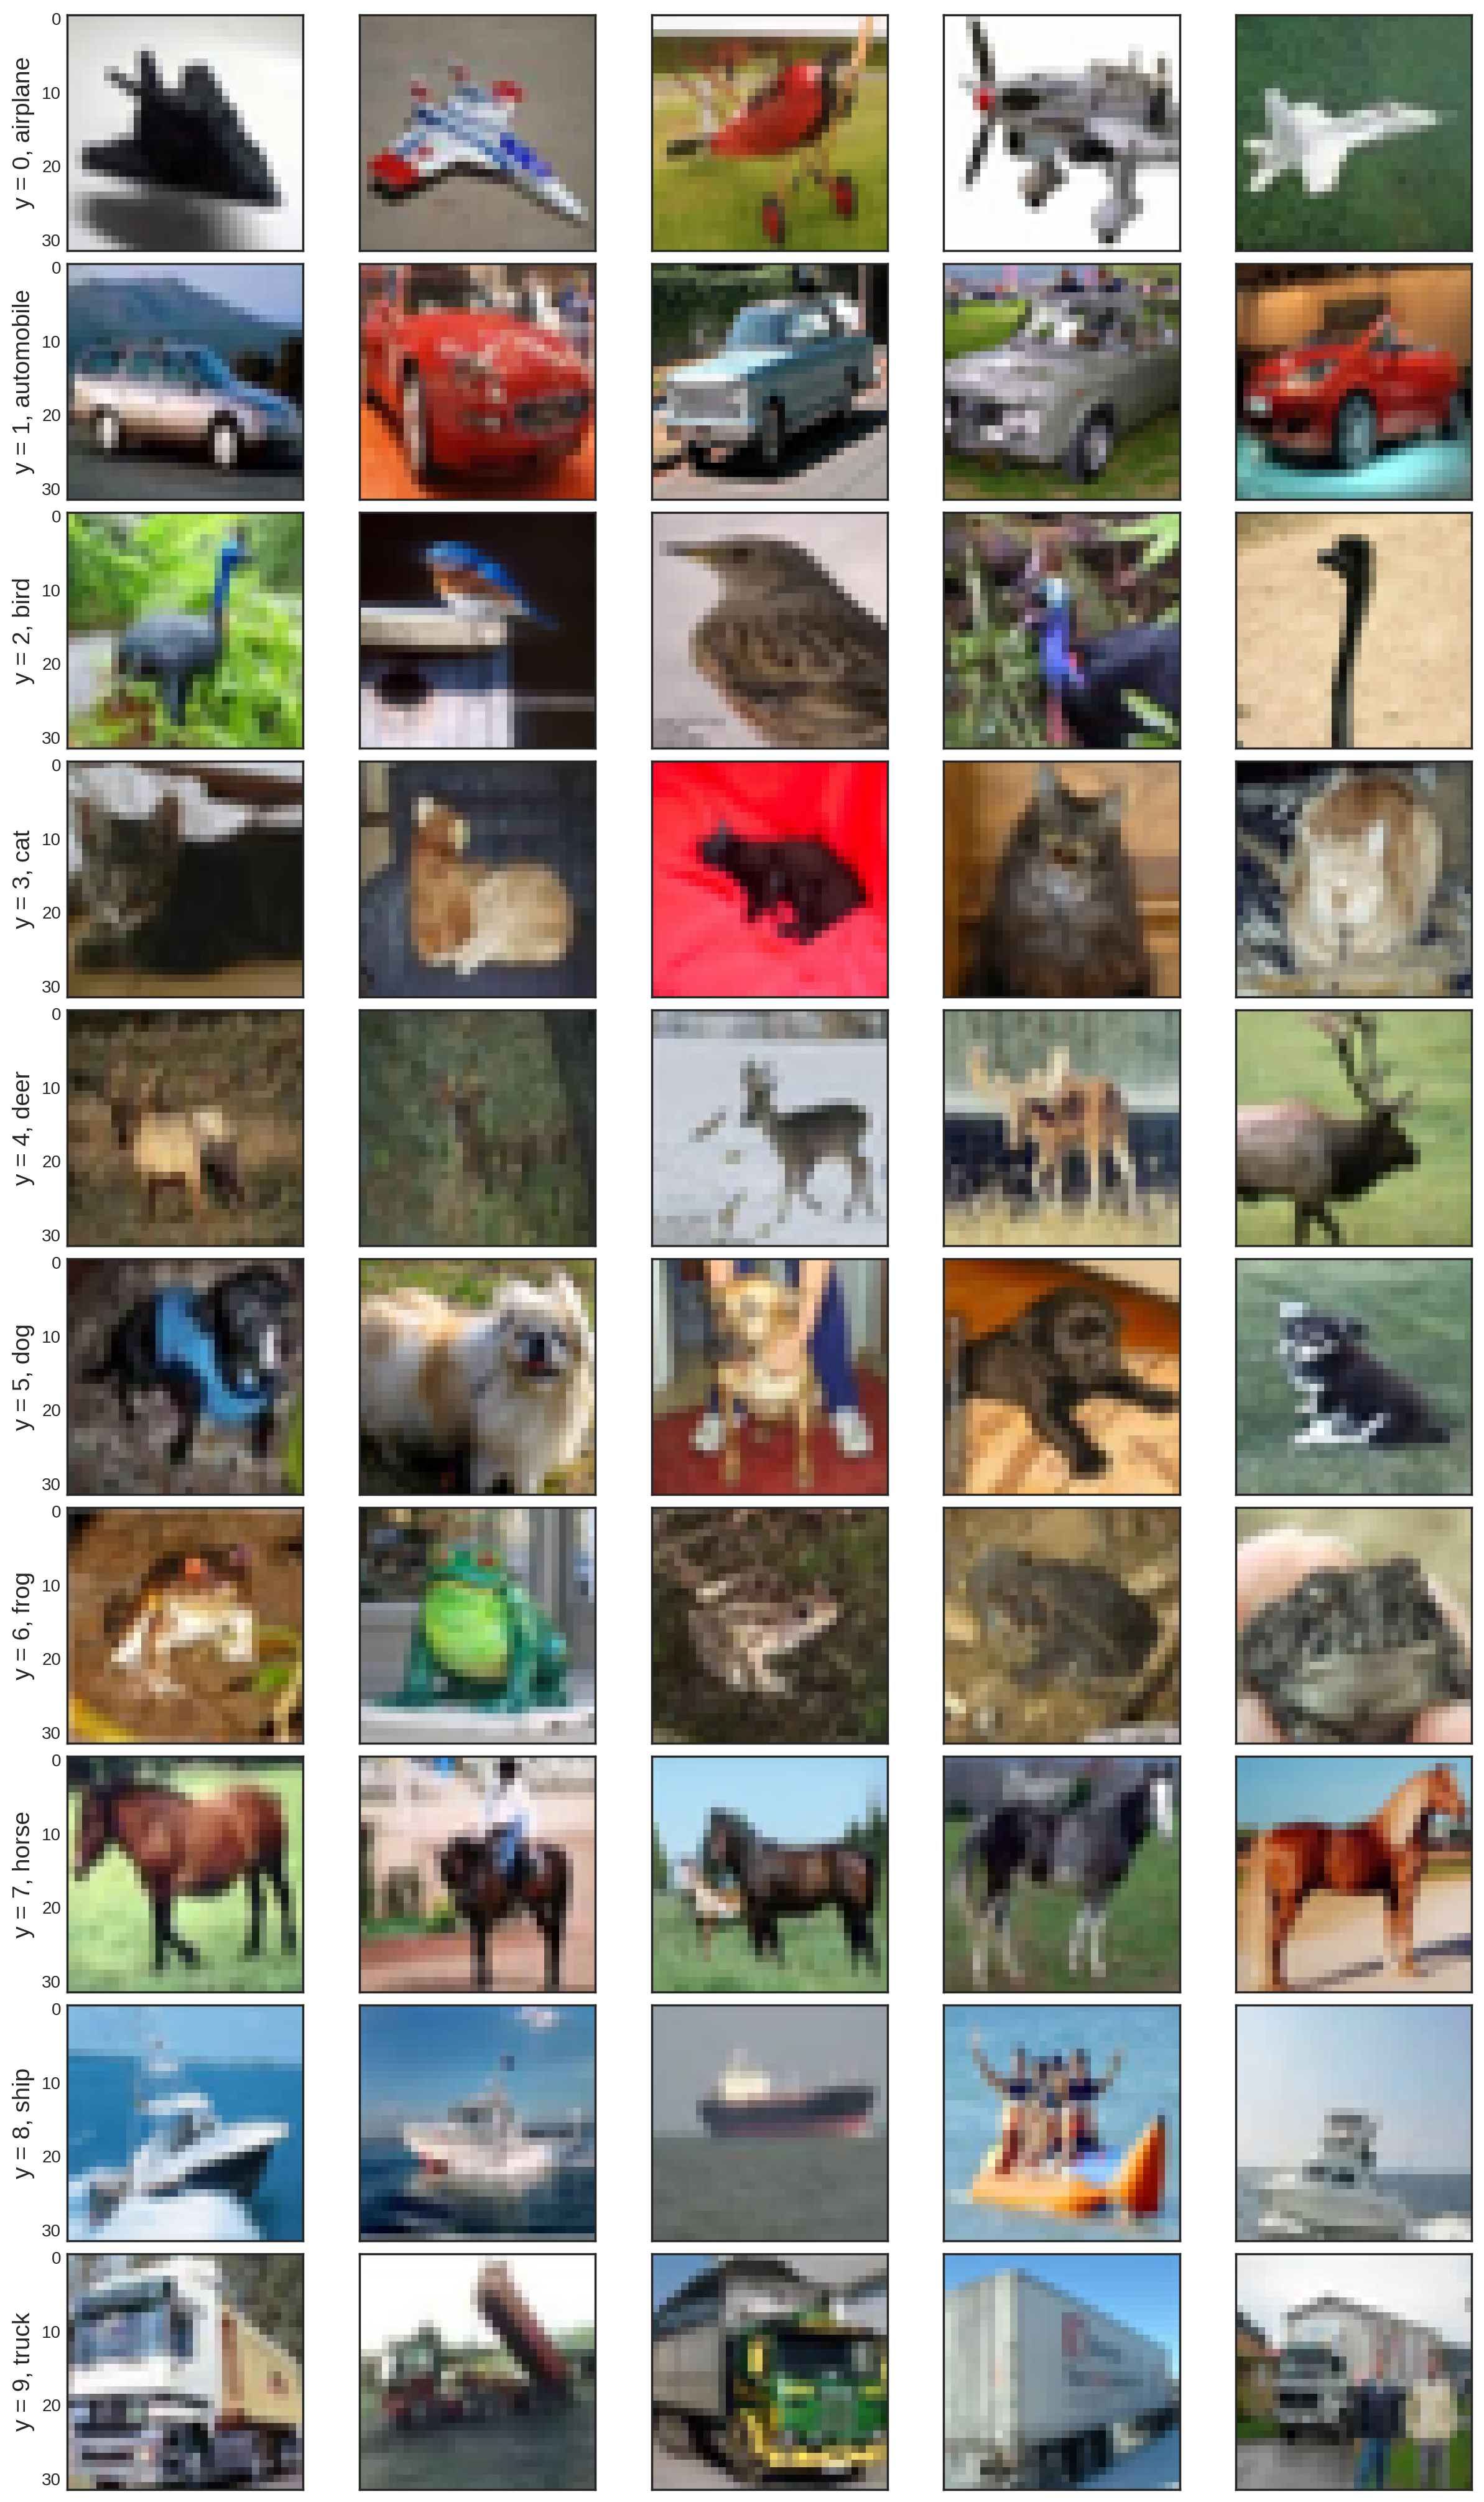

In [5]:
# visualize 5 images per class

labels = ["airplane", "automobile", "bird", "cat", "deer", "dog",
          "frog", "horse", "ship", "truck"]

fig = plt.figure(constrained_layout=True, figsize=(12, 20))
axes = fig.subplots(nrows=10, ncols=5, sharey=True)

for i in range(10):
  ims = X_train[y_train[:, 0]== i][:5]
  for j in range(5):
    axes[i, j].imshow(ims[j])
    if j != 0:
          axes[i, j].yaxis.set_visible(False)
    if j == 0:
          axes[i, j].set_ylabel(f"y = {i}, {labels[i]}", fontsize=14)
    axes[i, j].xaxis.set_visible(False)

---

## Step 2: Preprocess Data

In [6]:
# because intensity values of all 3 channles have the same scale (0 to 255)
# we can easily standardize data to have feature values between 0 and 1
X_train = X_train / 255.0
X_valid = X_valid / 255.0

In [7]:
# define a routine invoked at the end of each epoch to save the current model weights
# when training starts on Colab, you can find the file by opening the file navigation pane (click the files icon on the side bar)
# If you want to roll back to the best model, use: model = keras.models.load_model("my_model.h5")
checkpoint_cb = keras.callbacks.ModelCheckpoint("my_model.h5", save_best_only=True, verbose=1)

# define a routine that implement early stoping if it sees no more progress for 20 epochs
early_stopping_cb = keras.callbacks.EarlyStopping(patience=20, verbose=1)

# define a routine that reduces the leraning rate by multiplying 0.5 if it sees no improvements for 5 epochs
lr_scheduler = keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=5, verbose=1)


## Step 3: Create Callbacks


---



The [`fit()` method](https://www.tensorflow.org/api_docs/python/tf/keras/Sequential#fit) accepts a `callbacks` argument that lets us specify a list of callbacks, i.e., routines invoked at some specific point in time during training (e.g., at the start and end of training, at the start and end of each epoch, etc.)

We are going to experiment with the following 3 callbacks:

- [`ModelCheckpoint` callback](https://www.tensorflow.org/api_docs/python/tf/keras/callbacks/ModelCheckpoint): defines a checkpoint routine to save the current model weights at regular intervals (by default at the end of each epoch). We can configure it to save only the best model (so it overwrites the previously saved file).


-  [`EarlyStopping` callback](https://www.tensorflow.org/api_docs/python/tf/keras/callbacks/EarlyStopping): implements early stopping with a specified patience criterion to prevent overfitting.  It stops training early if it measures no progress on the validation set for a specified number of epochs (defined by the `patience` argument).



- [`ReduceLROnPlateau` callback](https://www.tensorflow.org/api_docs/python/tf/keras/callbacks/ReduceLROnPlateau): reduces the learning rate (learning rate decay) by a fixed factor when performance on the validation set has stopped improving.






---
## Step 4: Start building and training your model


Tips:

1) GPU backend is not guaranteed for free users on Colab. Its availability fluctuates from time to time. But using GPU can make your model training much faster. To enable GPU backend for your notebook: Choose Runtime at the navigation bar -> Change runtime type -> Hardware Accelerator -> Choose T4 GPU from the dropdown list.

2) A relatively large batch size (e.g., 128, 256, and 512) allows us to exploit the potential of vectorization, and can thereby make your training faster. With GPU backend, running one epoch should take no more than 4 seconds.


3) If you want to try [`SGD()`](https://www.tensorflow.org/api_docs/python/tf/keras/optimizers/SGD), use it with Nesterov momentum. Learning rate decay implemented through the `ReduceLROnPlateau` callback can also help.


4) Try to use Batch Norm (the [`BatchNormalization`](https://www.tensorflow.org/api_docs/python/tf/keras/layers/BatchNormalization) layer). Don't use Batch Norm for the output layer.

5) If you want to use both [`Dropout`](https://www.tensorflow.org/api_docs/python/tf/keras/layers/Dropout) and batch normalization, put a Dropout layer after a Batch Norm layer. Don't use Dropout for the output layer.

6) When using dropout, training loss and accuracy reported during training is not reliable, as they are evaluated on random subsets of the full model. Run `model.evaluate(X_train, y_train)` after training to get the training loss and accuracy without dropout. Compare it with the training set criterion (i.e., accuracy > 90% ).

7) [L2 regularization](https://www.tensorflow.org/api_docs/python/tf/keras/regularizers/L2) may also help.

8) Use the right initialization scheme.





### Your Final and Best Model

In [10]:
# Starter code

np.random.seed(1)
tf.random.set_seed(1)
# If you want to roll back to the best model, use: model = keras.models.load_model("my_model.h5")
checkpoint_cb = keras.callbacks.ModelCheckpoint("my_final_model.h5", save_best_only=True, verbose=1)

# define a routine that implement early stoping if it sees no more progress for 20 epochs
early_stopping_cb = keras.callbacks.EarlyStopping(patience=20, verbose=1)

# define a routine that reduces the leraning rate by multiplying 0.5 if it sees no improvements for 5 epochs
lr_scheduler = keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=5, verbose=1)


# Type you code below
model_final= Sequential([
    layers.Flatten(input_shape=(32, 32, 3)),
    layers.Dense(2048, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    layers.BatchNormalization(),
    layers.Dropout(0.1),
    layers.Dense(512, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    layers.BatchNormalization(),
    layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    layers.BatchNormalization(),
    layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    layers.BatchNormalization(),
    layers.Dense(10, activation='softmax', kernel_regularizer=regularizers.l2(0.001))
])

optimizer_fn = optimizers.SGD(
    learning_rate=0.01, momentum=0.95, nesterov=True
)

lossfn = losses.SparseCategoricalCrossentropy(from_logits=True)
model_final.compile(optimizer=optimizer_fn,
              loss=lossfn,
              metrics=['accuracy'])

model_final_output = model_final.fit(X_train,y_train, batch_size = 512, epochs=95, validation_data=[X_valid, y_valid], callbacks=[lr_scheduler, checkpoint_cb, early_stopping_cb])




Epoch 1/95
95/98 [============================>.] - ETA: 0s - loss: 5.2695 - accuracy: 0.3824
Epoch 1: val_loss improved from inf to 5.40790, saving model to my_final_model.h5
98/98 [==============================] - 4s 22ms/step - loss: 5.2599 - accuracy: 0.3844 - val_loss: 5.4079 - val_accuracy: 0.2580 - lr: 0.0100
Epoch 2/95
98/98 [==============================] - ETA: 0s - loss: 4.7470 - accuracy: 0.4782
Epoch 2: val_loss improved from 5.40790 to 4.77435, saving model to my_final_model.h5
98/98 [==============================] - 2s 19ms/step - loss: 4.7470 - accuracy: 0.4782 - val_loss: 4.7744 - val_accuracy: 0.4307 - lr: 0.0100
Epoch 3/95
97/98 [============================>.] - ETA: 0s - loss: 4.4083 - accuracy: 0.5131
Epoch 3: val_loss improved from 4.77435 to 4.53186, saving model to my_final_model.h5
98/98 [==============================] - 2s 20ms/step - loss: 4.4079 - accuracy: 0.5128 - val_loss: 4.5319 - val_accuracy: 0.4184 - lr: 0.0100
Epoch 4/95
94/98 [=================

In [11]:
model_final.summary()
train = model_final.evaluate(X_train, y_train)
valid = model_final.evaluate(X_valid, y_valid)
print(f"Training Accuracy = {train[1]}")
print(f"Validation Accuracy = {valid[1]}")


Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten_1 (Flatten)         (None, 3072)              0         
                                                                 
 dense_5 (Dense)             (None, 2048)              6293504   
                                                                 
 batch_normalization_4 (Bat  (None, 2048)              8192      
 chNormalization)                                                
                                                                 
 dropout_1 (Dropout)         (None, 2048)              0         
                                                                 
 dense_6 (Dense)             (None, 512)               1049088   
                                                                 
 batch_normalization_5 (Bat  (None, 512)               2048      
 chNormalization)                                     

### The 1st milestone model


In [7]:
# Starter code

np.random.seed(1)
tf.random.set_seed(1)


# Type you code below
model_one = Sequential([
    layers.Flatten(input_shape=(32, 32, 3)),
    layers.Dense(512, activation='relu'),
    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dense(64, activation='relu'),
    layers.BatchNormalization(),
    layers.Dense(10, activation='softmax')
])


optimizerfn = tf.keras.optimizers.Adam(
    learning_rate=0.01, beta_1=0.9, beta_2=0.999, epsilon=1e-07,
    amsgrad=False, name='Adam'
)
lossfn = losses.SparseCategoricalCrossentropy(from_logits=True)
model_one.compile(optimizer=optimizerfn,
              loss=lossfn,
              metrics=['accuracy'])


model_one_output = model_one.fit(X_train,y_train, batch_size = 128, epochs=50, validation_data=[X_valid, y_valid], callbacks=[early_stopping_cb])
model_one.summary()




Epoch 1/50
391/391 [==============================] - 7s 9ms/step - loss: 1.9029 - accuracy: 0.3065 - val_loss: 4.0938 - val_accuracy: 0.1403
Epoch 2/50
391/391 [==============================] - 3s 8ms/step - loss: 1.6771 - accuracy: 0.3961 - val_loss: 1.8083 - val_accuracy: 0.3605
Epoch 3/50
391/391 [==============================] - 3s 7ms/step - loss: 1.5915 - accuracy: 0.4286 - val_loss: 4.0866 - val_accuracy: 0.1631
Epoch 4/50
391/391 [==============================] - 4s 9ms/step - loss: 1.5380 - accuracy: 0.4473 - val_loss: 1.7977 - val_accuracy: 0.3599
Epoch 5/50
391/391 [==============================] - 3s 8ms/step - loss: 1.5126 - accuracy: 0.4559 - val_loss: 1.8996 - val_accuracy: 0.3539
Epoch 6/50
391/391 [==============================] - 3s 7ms/step - loss: 1.4803 - accuracy: 0.4684 - val_loss: 1.6874 - val_accuracy: 0.4094
Epoch 7/50
391/391 [==============================] - 3s 8ms/step - loss: 1.4516 - accuracy: 0.4782 - val_loss: 1.6755 - val_accuracy: 0.4026
Epoch 

###   The 2nd milestone model

In [8]:
# Starter code

np.random.seed(1)
tf.random.set_seed(1)


# Type you code below
model_two = Sequential([
    layers.Flatten(input_shape=(32, 32, 3)),
    layers.Dense(512, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    layers.BatchNormalization(),
    layers.Dense(256, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    layers.BatchNormalization(),
    layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    layers.BatchNormalization(),
    layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    layers.BatchNormalization(),
    layers.Dense(10, activation='softmax')
])

optimizer_fn = optimizers.SGD(
    learning_rate=0.01, momentum=0.95, nesterov=True
)

lossfn = losses.SparseCategoricalCrossentropy(from_logits=True)
model_two.compile(optimizer=optimizer_fn,       # can also set it to 'sgd' if you are okay to use the default lr
              loss=lossfn,
              metrics=['accuracy'])

model_two_output = model_two.fit(X_train,y_train, batch_size = 128, epochs=75, validation_data=[X_valid, y_valid], callbacks=[lr_scheduler])
model_two.evaluate(X_train, y_train)



Epoch 1/75


/usr/local/lib/python3.10/dist-packages/keras/src/backend.py:5729: UserWarning: "`sparse_categorical_crossentropy` received `from_logits=True`, but the `output` argument was produced by a Softmax activation and thus does not represent logits. Was this intended?
  output, from_logits = _get_logits(


391/391 [==============================] - 6s 11ms/step - loss: 3.0701 - accuracy: 0.3895 - val_loss: 2.8252 - val_accuracy: 0.3937 - lr: 0.0100
Epoch 2/75
391/391 [==============================] - 3s 9ms/step - loss: 2.5457 - accuracy: 0.4581 - val_loss: 2.6880 - val_accuracy: 0.3582 - lr: 0.0100
Epoch 3/75
391/391 [==============================] - 3s 8ms/step - loss: 2.2370 - accuracy: 0.4847 - val_loss: 2.4928 - val_accuracy: 0.3635 - lr: 0.0100
Epoch 4/75
391/391 [==============================] - 3s 8ms/step - loss: 2.0216 - accuracy: 0.5039 - val_loss: 2.3401 - val_accuracy: 0.3585 - lr: 0.0100
Epoch 5/75
391/391 [==============================] - 4s 10ms/step - loss: 1.8752 - accuracy: 0.5093 - val_loss: 2.0737 - val_accuracy: 0.4176 - lr: 0.0100
Epoch 6/75
391/391 [==============================] - 3s 9ms/step - loss: 1.7644 - accuracy: 0.5207 - val_loss: 2.3239 - val_accuracy: 0.3483 - lr: 0.0100
Epoch 7/75
391/391 [==============================] - 3s 8ms/step - loss: 1.689

[0.36704063415527344, 0.9557399749755859]

###   The 3rd milestone model

In [14]:
# Starter code

np.random.seed(1)
tf.random.set_seed(1)
# If you want to roll back to the best model, use: model = keras.models.load_model("my_model.h5")
checkpoint_cb = keras.callbacks.ModelCheckpoint("my_model_three.h5", save_best_only=True, verbose=1)

# define a routine that implement early stoping if it sees no more progress for 20 epochs
early_stopping_cb = keras.callbacks.EarlyStopping(patience=20, verbose=1)

# define a routine that reduces the leraning rate by multiplying 0.5 if it sees no improvements for 5 epochs
lr_scheduler = keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=5, verbose=1)


# Type you code below
model_three= Sequential([
    layers.Flatten(input_shape=(32, 32, 3)),
    layers.Dense(2048, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    layers.BatchNormalization(),
    layers.Dropout(0.1),
    layers.Dense(512, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    layers.BatchNormalization(),
    layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    layers.BatchNormalization(),
    layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    layers.BatchNormalization(),
    layers.Dense(10, activation='softmax', kernel_regularizer=regularizers.l2(0.001))
])

optimizer_fn = optimizers.SGD(
    learning_rate=0.01, momentum=0.95, nesterov=True
)

lossfn = losses.SparseCategoricalCrossentropy(from_logits=True)
model_three.compile(optimizer=optimizer_fn,
              loss=lossfn,
              metrics=['accuracy'])

model_three_output = model_three.fit(X_train,y_train, batch_size = 512, epochs=95, validation_data=[X_valid, y_valid], callbacks=[lr_scheduler, checkpoint_cb, early_stopping_cb])
model_three.summary()
model_three.evaluate(X_train, y_train)
model_three.evaluate(X_valid, y_valid)


Epoch 1/95


/usr/local/lib/python3.10/dist-packages/keras/src/backend.py:5729: UserWarning: "`sparse_categorical_crossentropy` received `from_logits=True`, but the `output` argument was produced by a Softmax activation and thus does not represent logits. Was this intended?
  output, from_logits = _get_logits(


95/98 [============================>.] - ETA: 0s - loss: 5.2643 - accuracy: 0.3891
Epoch 1: val_loss improved from inf to 5.25009, saving model to my_model_three.h5
98/98 [==============================] - 4s 22ms/step - loss: 5.2548 - accuracy: 0.3909 - val_loss: 5.2501 - val_accuracy: 0.3386 - lr: 0.0100
Epoch 2/95
 1/98 [..............................] - ETA: 1s - loss: 4.9219 - accuracy: 0.4492

/usr/local/lib/python3.10/dist-packages/keras/src/engine/training.py:3079: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


94/98 [===========================>..] - ETA: 0s - loss: 4.7427 - accuracy: 0.4807
Epoch 2: val_loss improved from 5.25009 to 4.72409, saving model to my_model_three.h5
98/98 [==============================] - 1s 15ms/step - loss: 4.7383 - accuracy: 0.4807 - val_loss: 4.7241 - val_accuracy: 0.4492 - lr: 0.0100
Epoch 3/95
97/98 [============================>.] - ETA: 0s - loss: 4.4055 - accuracy: 0.5159
Epoch 3: val_loss improved from 4.72409 to 4.50202, saving model to my_model_three.h5
98/98 [==============================] - 1s 15ms/step - loss: 4.4047 - accuracy: 0.5160 - val_loss: 4.5020 - val_accuracy: 0.4337 - lr: 0.0100
Epoch 4/95
96/98 [============================>.] - ETA: 0s - loss: 4.1166 - accuracy: 0.5395
Epoch 4: val_loss improved from 4.50202 to 4.32921, saving model to my_model_three.h5
98/98 [==============================] - 2s 16ms/step - loss: 4.1147 - accuracy: 0.5395 - val_loss: 4.3292 - val_accuracy: 0.4138 - lr: 0.0100
Epoch 5/95
98/98 [========================

[2.2959234714508057, 0.5594000220298767]

<b>Double click this cell to enter best model accuracy metrics for different attempts.</b>  

1. The final model: (Training accuracy: 0.9945 validation accuracy: 0.5503)
2. The 1st milestone model: (Training accuracy: 0.6405; validation Accuracy: 0.4823)
3. The 2nd milestone model: (Training accuracy: 0.9557; validation Accuracy: 0.5458)
4. The 3rd milestone model: (Training accuracy: 0.9914; validation Accuracy: 0.5594)


## Step 5: Briefly describe your journey and what you've learned in the process

Double click this cell to enter your answer below:

Your Answer:
The first thing before started is to list what significantly can affect the accuracy of both training and validation such as layers, number of nodes, normalization, mini-batch train, momentum, others that mention in the step 3.

---
###First Model
**Optimizer**: In the first model, i build a simple sequential model as the result and , knowingly that the epoch are mostly need to be less than 4 seconds.I recognize that ADAM has an advantage of converging the error faster than SGD *(without using momentum)* since there is beta that tracks the trend of the data . However, in a long running training data (large epoch), there is a case where SGD can have a better accuracy.

**Layers**: At this milestone, i also cover tuning the number of layers and nodes of each layer. It mostly based on experimentation of random tuning with multiplication of 64 and using only 10 epoch due to GPU constrain (Colab free).
```
unit_1 = hp.Int('units_1', min_value=32, max_value=512, step=64)
unit_2 = hp.Int('units_2', min_value=32, max_value=512, step=64)
unit_3 = hp.Int('units_3', min_value=32, max_value=512, step=64)
unit_4 = hp.Int('units_4', min_value=32, max_value=512, step=64)
```

I also use **batchnormalization** in order to make sure it manage the variance of the training data aswell.


**Learning rate**: The experimentation also cover the learning rate of the model. Using a binary search based on with based on log of ten.
```
learning_rate = hp.Float("learning_rate", min_value=0.0001, max_value=10,
step=3, sampling="log")
```
---
###Second Model
At the second model, i try to use SGD optimization with momentum. Besides that, i also use the learning rate reducer if there is no improvement. With that, arguably the initial learning rate would not be matter that much. However, the momentum still. In this case, i made another random search case with ten loop constrain for momentum to search the best.

The learning reducer is the main actor here. The accuracy is higher since the learning rate can adjust to a smaller number as the magnitude to the optimal accuracy is lower.

Secondly, i also add l2 regularization. It helps the overfitting, this can directly seen in the valid accuracy which increase which means it is closer to maximum point.

---

###Third Model

The third model comes into conclusion, I realized that the complexity of the data is more than the precvious model. **This means that i need to increase the number of nodes in the layer.**

Additionally, i also use **drop out and adding checkpoint as a callback**. This enhance the performance by selecting only some of the nodes while saving the best model. which means, it is making sure that the next epoch will continue with the best model.

Besides that, to shorten the runtime,** i increase the batch size 4 times from the previous model.** This made the runtime much faster yet the memories much larger. The reason behind it is because batchsize determine the number of running iteration at a time.

I also **add earlystop callback**, since i recognize there is a plateau around epoch 60-ish. The running code can determine on its own when to finish to make sure it is optimized.